# Лабораторная работа №13. Object Detection: IoU, NMS и Precision–Recall

Условие — в [методичке](CSE5382_15_лабораторных_работ_математические_методы_in_CV.md), раздел «Лабораторная работа №13».

**Данные.** Синтетические: 40 «изображений» 640×480, на каждом несколько эталонных рамок и набор «предсказаний детектора», сгенерированных с типичными дефектами — дубликатами, неточной локализацией, ложными срабатываниями на фоне и пропусками. Генератор — в ноутбуке, seed зафиксирован.

> **Что нужно заменить перед сдачей.** Шаг 1 задания — *получить predictions настоящего детектора* (например, YOLO) на размеченных изображениях. Здесь предсказания смоделированы, поэтому работа проверяет математику IoU, NMS и PR-кривой, но ничего не говорит о качестве какого-либо реального детектора. Шаг 10 (сравнение с библиотечными mAP50 / mAP50-95) не выполнен: библиотечный расчёт требует реального детектора и набора в формате COCO. Собственные AP50 и AP50-95 посчитаны.

## 1. О чём эта работа

### Знакомый пример

Камера телефона обводит лица рамками. Автопилот обводит машины и пешеходов. Задача **детекции** — не просто сказать «на фото есть кошка», а указать, **где** она: нарисовать прямоугольник.

### Основная идея

Детектор не выдаёт один аккуратный прямоугольник на объект. Он выдаёт сотни кандидатов, каждый с числом — уверенностью. Вокруг одного объекта обычно оказывается целая стопка почти одинаковых рамок. Отсюда три вопроса:

1. Как измерить, насколько рамка совпала с правильной? — **IoU**.
2. Как из стопки рамок вокруг одного объекта оставить одну? — **NMS**.
3. Как одним графиком описать качество детектора при любом пороге уверенности? — **кривая precision–recall**.

### Понятия

- **Bounding box** — прямоугольник, заданный двумя углами: $(x_1,y_1,x_2,y_2)$ — левый верхний и правый нижний (формат xyxy).
- **Confidence** — уверенность детектора в рамке, от 0 до 1.
- **Ground truth (GT)** — эталонные рамки из разметки.
- **IoU** (Intersection over Union) — площадь пересечения двух рамок, делённая на площадь их объединения. 1 — совпали, 0 — не пересекаются. (В лабораторной 10 то же самое считалось для масок.)
- **NMS** (non-maximum suppression) — жадная процедура: взять самую уверенную рамку, выбросить все, что сильно с ней пересекаются, повторить для оставшихся.
- **Жадный алгоритм** — на каждом шаге делает локально лучший выбор и никогда его не пересматривает.
- **TP / FP / FN для детекции.** Предсказание — TP, если его IoU с ещё не занятой GT-рамкой не меньше порога (обычно 0.5); иначе FP. GT-рамка, которой не досталось предсказания, — FN.
- **Precision** — доля верных среди предсказаний; **recall** — доля найденных объектов.
- **AP** (average precision) — площадь под кривой precision–recall. **mAP** — среднее AP по классам. **AP50** — при пороге IoU 0.5; **AP50-95** — среднее по порогам от 0.5 до 0.95 с шагом 0.05.

### Формулы

$$\mathrm{IoU}(A,B)=\frac{\mathrm{area}(A\cap B)}{\mathrm{area}(A\cup B)},\qquad \mathrm{area}(A\cup B)=\mathrm{area}(A)+\mathrm{area}(B)-\mathrm{area}(A\cap B)$$

$$\mathrm{Precision}=\frac{TP}{TP+FP},\qquad \mathrm{Recall}=\frac{TP}{N_{GT}}$$

$N_{GT}$ — общее число эталонных объектов.

In [1]:
import numpy as np
import torch
import torchvision
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.dpi": 80})

SEED = 0
N_IMAGES, IMG_W, IMG_H = 40, 640, 480
NMS_THR = 0.5            # порог IoU в NMS
MATCH_IOU = 0.5          # порог IoU для зачёта предсказания как TP
CONF_OPERATING = 0.5     # рабочий порог confidence для таблицы

## 2. Вопрос 1 — IoU двух рамок

> Для A=(10,20,70,90), B=(40,50,100,110) найдите IoU.

**Шаг 1. Пересечение.** Пересечение двух прямоугольников — прямоугольник: левый край — больший из левых, правый — меньший из правых; так же по вертикали.

- по $x$: от $\max(10,40)=40$ до $\min(70,100)=70$ → ширина 30;
- по $y$: от $\max(20,50)=50$ до $\min(90,110)=90$ → высота 40;
- площадь: $30\cdot40=1200$.

**Шаг 2. Площади.** $A$: $(70-10)(90-20)=60\cdot70=4200$. $B$: $(100-40)(110-50)=60\cdot60=3600$.

**Шаг 3. Объединение.** Если сложить площади, пересечение посчитается дважды: $4200+3600-1200=6600$.

**Шаг 4.** $\mathrm{IoU}=1200/6600=2/11\approx0.1818$.

**Смысл.** Рамки перекрываются углом; общая часть — 18 % их объединения. При стандартном пороге 0.5 такое предсказание не засчитали бы. IoU строг: рамка того же размера, сдвинутая на треть ширины, даёт IoU всего 0.5.

**Если рамки не пересекаются**, «ширина» или «высота» пересечения получается отрицательной. Её нужно заменить нулём (`max(0, ...)`), иначе произведение двух отрицательных чисел дало бы положительную «площадь».

In [2]:
def iou_xyxy(a, b):
    x1 = max(a[0], b[0]); y1 = max(a[1], b[1])
    x2 = min(a[2], b[2]); y2 = min(a[3], b[3])
    inter = max(0.0, x2 - x1) * max(0.0, y2 - y1)
    aa = max(0.0, a[2] - a[0]) * max(0.0, a[3] - a[1])
    bb = max(0.0, b[2] - b[0]) * max(0.0, b[3] - b[1])
    return inter / (aa + bb - inter + 1e-12)

A, B = (10, 20, 70, 90), (40, 50, 100, 110)
print("IoU(A, B) =", round(iou_xyxy(A, B), 4), " = 2/11 =", round(2 / 11, 4))
print("не пересекаются:", iou_xyxy((0, 0, 10, 10), (20, 20, 30, 30)))
print("без max(0, ·) «пересечение» было бы:", (min(10, 30) - max(0, 20)) * (min(10, 30) - max(0, 20)), "— ложная положительная площадь")
print("рамка 60×60, сдвинутая на 20 px (треть ширины): IoU =", round(iou_xyxy((0, 0, 60, 60), (20, 0, 80, 60)), 3))

IoU(A, B) = 0.1818  = 2/11 = 0.1818
не пересекаются: 0.0
без max(0, ·) «пересечение» было бы: 100 — ложная положительная площадь
рамка 60×60, сдвинутая на 20 px (треть ширины): IoU = 0.5


**Итог вопроса 1:** $\mathrm{IoU}\approx0.1818$.

## 3. Вопрос 2 — NMS и накопленные precision/recall

> Для A,B,C с confidences .95,.85,.70 и IoU(A,B)=.65, IoU(A,C)=.20, IoU(B,C)=.55 выполните NMS при threshold=.5. Затем для TP,FP,TP,TP,FP при N_GT=4 найдите накопленные precision/recall.

### NMS

Рамки уже упорядочены по уверенности: A (0.95), B (0.85), C (0.70).

1. Берём самую уверенную — **A**. Оставляем. Сравниваем с ней остальные:
   - $\mathrm{IoU}(A,B)=0.65>0.5$ → B считается дубликатом A, **удаляется**;
   - $\mathrm{IoU}(A,C)=0.20\le0.5$ → C остаётся кандидатом.
2. Следующая из оставшихся — **C**. Оставляем. Сравнивать больше не с кем.

Результат: **A и C**.

**Тонкость.** $\mathrm{IoU}(B,C)=0.55>0.5$, но C не удалена: B к этому моменту уже выброшена и никого подавлять не может. Если бы A не существовало, B осталась бы и подавила C. Результат NMS зависит от порядка — в этом и состоит жадность.

### Precision и recall по шагам

Предсказания отсортированы по убыванию уверенности. Идём сверху вниз и после каждого пересчитываем.

| шаг | исход | TP всего | FP всего | precision = TP/(TP+FP) | recall = TP/4 |
|---|---|---|---|---|---|
| 1 | TP | 1 | 0 | 1/1 = 1.000 | 0.25 |
| 2 | FP | 1 | 1 | 1/2 = 0.500 | 0.25 |
| 3 | TP | 2 | 1 | 2/3 = 0.667 | 0.50 |
| 4 | TP | 3 | 1 | 3/4 = 0.750 | 0.75 |
| 5 | FP | 3 | 2 | 3/5 = 0.600 | 0.75 |

**Смысл.** Каждая строка — рабочая точка детектора при пороге уверенности «взять первые $k$ предсказаний». Recall при движении вниз никогда не убывает (объекты только добавляются). Precision скачет: падает на каждом FP и частично восстанавливается на каждом TP. Четвёртый объект не найден — recall остановился на 0.75.

In [3]:
def nms_from_iou(order, iou, thr):
    """NMS по готовой таблице IoU: order — имена по убыванию confidence."""
    keep, removed = [], set()
    for a in order:
        if a in removed: continue
        keep.append(a)
        for b in order:
            if b != a and b not in keep and b not in removed and iou[frozenset((a, b))] > thr:
                removed.add(b); print(f"  {a} подавляет {b}: IoU = {iou[frozenset((a, b))]} > {thr}")
    return keep

iou_tab = {frozenset("AB"): 0.65, frozenset("AC"): 0.20, frozenset("BC"): 0.55}
print("NMS при threshold 0.5:"); print("  остаются:", nms_from_iou(["A", "B", "C"], iou_tab, 0.5))
print("если бы A не было:"); print("  остаются:", nms_from_iou(["B", "C"], iou_tab, 0.5))

def pr_from_flags(is_tp, n_gt):
    is_tp = np.asarray(is_tp, dtype=float)
    tp = np.cumsum(is_tp); fp = np.cumsum(1 - is_tp)
    return tp / (tp + fp), tp / n_gt

prec, rec = pr_from_flags([1, 0, 1, 1, 0], 4)
print("\nprecision:", np.round(prec, 3)); print("recall   :", rec)

NMS при threshold 0.5:
  A подавляет B: IoU = 0.65 > 0.5
  остаются: ['A', 'C']
если бы A не было:
  B подавляет C: IoU = 0.55 > 0.5
  остаются: ['B']

precision: [1.    0.5   0.667 0.75  0.6  ]
recall   : [0.25 0.25 0.5  0.75 0.75]


**Итог вопроса 2:** после NMS остаются A и C; precision = [1, 0.5, 0.667, 0.75, 0.6], recall = [0.25, 0.25, 0.5, 0.75, 0.75].

## 4. Задание 3 — код и эксперимент

### Шаг 1. Предсказания в формате xyxy + confidence

Генератор для каждого GT-объекта создаёт:

- с вероятностью 0.9 — «основное» предсказание со слегка сдвинутой рамкой и высокой уверенностью;
- 0–3 **дубликата** — рамки вокруг того же объекта с меньшей уверенностью;
- с вероятностью 0.12 — **плохо локализованное** предсказание (сильно сдвинутое).

Плюс на каждом изображении — несколько случайных **фоновых** рамок с невысокой уверенностью. Класс один.

In [4]:
def make_dataset(seed=SEED, n_images=N_IMAGES):
    rng = np.random.default_rng(seed)
    data = []
    for _ in range(n_images):
        gts = []
        for _ in range(rng.integers(2, 6)):
            w, h = rng.uniform(50, 170), rng.uniform(50, 170)
            x1, y1 = rng.uniform(0, IMG_W - w), rng.uniform(0, IMG_H - h)
            gts.append([x1, y1, x1 + w, y1 + h])
        gts = np.array(gts)
        boxes, scores = [], []
        def jitter(g, rel):
            w, h = g[2] - g[0], g[3] - g[1]
            return g + rng.normal(0, rel, 4) * np.array([w, h, w, h])
        for g in gts:
            if rng.random() < 0.9:
                conf = rng.uniform(0.55, 0.99)
                boxes.append(jitter(g, 0.04)); scores.append(conf)
                for _ in range(rng.integers(0, 4)):                       # дубликаты
                    boxes.append(jitter(g, 0.08)); scores.append(max(0.05, conf - rng.uniform(0.05, 0.4)))
            if rng.random() < 0.12:                                       # плохая локализация
                w, h = g[2] - g[0], g[3] - g[1]
                boxes.append(g + np.array([0.45 * w, 0.4 * h, 0.45 * w, 0.4 * h])); scores.append(rng.uniform(0.3, 0.8))
        for _ in range(rng.poisson(1.5)):                                 # фон
            w, h = rng.uniform(40, 150), rng.uniform(40, 150)
            x1, y1 = rng.uniform(0, IMG_W - w), rng.uniform(0, IMG_H - h)
            boxes.append(np.array([x1, y1, x1 + w, y1 + h])); scores.append(rng.uniform(0.05, 0.6))
        data.append(dict(gt=gts, boxes=np.array(boxes).reshape(-1, 4), scores=np.array(scores)))
    return data

data = make_dataset()
N_GT = sum(len(d["gt"]) for d in data); N_PRED = sum(len(d["boxes"]) for d in data)
print(f"изображений: {len(data)}, GT-объектов: {N_GT}, предсказаний до NMS: {N_PRED} ({N_PRED / N_GT:.2f} на объект)")
print("пример, изображение 0: GT", data[0]["gt"].shape, " boxes", data[0]["boxes"].shape, " scores", np.round(data[0]["scores"], 2))

изображений: 40, GT-объектов: 147, предсказаний до NMS: 405 (2.76 на объект)
пример, изображение 0: GT (5, 4)  boxes (13, 4)  scores [0.85 0.66 0.63 0.69 0.56 0.7  0.5  0.59 0.39 0.38 0.39 0.53 0.54]


### Шаги 2–3. IoU для пары и векторный вариант

Векторная функция считает сразу всю таблицу IoU между $N$ и $M$ рамками. Приём — broadcasting: массив формы `(N, 1, 4)` сравнивается с массивом формы `(1, M, 4)`, и NumPy сам «размножает» их до `(N, M, 4)`.

In [5]:
def iou_matrix(a, b):
    """IoU каждой рамки из a (N×4) с каждой из b (M×4) → N×M."""
    a = np.asarray(a, dtype=np.float64).reshape(-1, 4); b = np.asarray(b, dtype=np.float64).reshape(-1, 4)
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1]); area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-12)

print("ручной пример вопроса 1, векторная версия:", round(iou_matrix([A], [B])[0, 0], 4))
bx = data[0]["boxes"]
loop = np.array([[iou_xyxy(p, q) for q in bx] for p in bx])
print("векторная == попарная на изображении 0:", np.allclose(iou_matrix(bx, bx), loop))
print("сравнение с torchvision.ops.box_iou:", np.allclose(iou_matrix(bx, bx), torchvision.ops.box_iou(torch.tensor(bx), torch.tensor(bx)).numpy()))

ручной пример вопроса 1, векторная версия: 0.1818
векторная == попарная на изображении 0: True
сравнение с torchvision.ops.box_iou: True


### Шаги 4–5. Greedy NMS и сравнение с torchvision

Алгоритм в четыре строки: (1) отсортировать по убыванию confidence; (2) взять первую рамку в результат; (3) удалить из списка все рамки с IoU выше порога относительно неё; (4) повторять, пока список не пуст.

совпадение с torchvision.ops.nms: 40 из 40 изображений
рамок до NMS: 405, после: 196 (GT-объектов: 147)


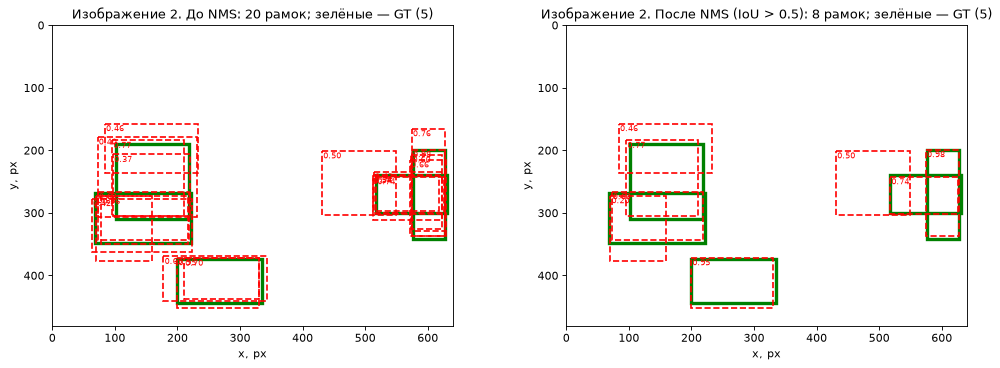

In [6]:
def nms_greedy(boxes, scores, thr=NMS_THR):
    """Возвращает индексы оставленных рамок в порядке убывания confidence."""
    order = np.argsort(-scores, kind="stable")          # сортировка по confidence
    keep = []
    while len(order) > 0:
        best = order[0]                                 # самая уверенная из оставшихся
        keep.append(best)
        if len(order) == 1: break
        ious = iou_matrix(boxes[best], boxes[order[1:]])[0]
        order = order[1:][ious <= thr]                  # удаляем всё, что перекрывается с ней сильнее порога
    return np.array(keep, dtype=int)

same = 0
for d in data:
    mine = nms_greedy(d["boxes"], d["scores"], NMS_THR)
    ref = torchvision.ops.nms(torch.tensor(d["boxes"], dtype=torch.float64), torch.tensor(d["scores"], dtype=torch.float64), NMS_THR).numpy()
    same += int(np.array_equal(mine, ref))
    d["keep"] = mine
n_after = sum(len(d["keep"]) for d in data)
print(f"совпадение с torchvision.ops.nms: {same} из {len(data)} изображений")
print(f"рамок до NMS: {N_PRED}, после: {n_after} (GT-объектов: {N_GT})")

def draw(ax, boxes, color, lw=1.5, ls="-", scores=None):
    for i, b in enumerate(boxes):
        ax.add_patch(Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec=color, lw=lw, ls=ls))
        if scores is not None: ax.text(b[0] + 2, b[1] + 12, f"{scores[i]:.2f}", color=color, fontsize=7)

k = int(np.argmax([len(d["boxes"]) for d in data]))
d = data[k]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
for a_, (idx, title) in zip(ax, [(np.arange(len(d["boxes"])), f"До NMS: {len(d['boxes'])} рамок"), (d["keep"], f"После NMS (IoU > {NMS_THR}): {len(d['keep'])} рамок")]):
    draw(a_, d["gt"], "green", lw=3); draw(a_, d["boxes"][idx], "red", ls="--", scores=d["scores"][idx])
    a_.set(xlim=(0, IMG_W), ylim=(IMG_H, 0), title=f"Изображение {k}. {title}; зелёные — GT ({len(d['gt'])})", xlabel="x, px", ylabel="y, px"); a_.set_aspect("equal")
plt.tight_layout(); plt.show()

### Шаги 6–8. Сопоставление с GT и накопленные TP/FP

Все предсказания со всех изображений складываются в один список и сортируются по confidence. Для каждого по очереди:

- среди GT **того же изображения**, ещё не занятых, ищем рамку с наибольшим IoU;
- если IoU ≥ порога — это TP, GT помечается занятой;
- иначе — FP. В частности, вторая рамка на уже найденном объекте — FP: один объект засчитывается один раз.

In [7]:
def evaluate(data, keep_key="keep", match_iou=MATCH_IOU):
    """Сопоставление предсказаний с GT. Возвращает отсортированные записи и число GT."""
    recs = []
    for img_id, d in enumerate(data):
        idx = d[keep_key] if keep_key else np.arange(len(d["boxes"]))
        for i in idx: recs.append((d["scores"][i], img_id, i))
    recs.sort(key=lambda r: -r[0])
    used = [np.zeros(len(d["gt"]), bool) for d in data]
    out = []
    for score, img_id, i in recs:
        d = data[img_id]
        ious = iou_matrix(d["boxes"][i], d["gt"])[0] if len(d["gt"]) else np.zeros(0)
        free = np.where(~used[img_id], ious, -1.0)
        j = int(np.argmax(free)) if len(free) else -1
        tp = j >= 0 and free[j] >= match_iou
        if tp: used[img_id][j] = True
        out.append(dict(score=score, img=img_id, idx=i, tp=bool(tp), gt=j if tp else -1, best_iou=float(ious.max()) if len(ious) else 0.0))
    return out, used

def pr_curve(recs, n_gt):
    flags = np.array([r["tp"] for r in recs], dtype=float)
    tp = np.cumsum(flags); fp = np.cumsum(1 - flags)
    return tp / np.maximum(tp + fp, 1e-12), tp / n_gt

def average_precision(prec, rec):
    """Площадь под PR-кривой с монотонной огибающей precision (способ COCO/VOC2010+)."""
    mrec = np.concatenate([[0.0], rec, [rec[-1] if len(rec) else 0.0]])
    mpre = np.concatenate([[1.0], prec, [0.0]])
    for i in range(len(mpre) - 2, -1, -1):
        mpre[i] = max(mpre[i], mpre[i + 1])            # precision «справа» не может быть больше
    return float(np.sum((mrec[1:] - mrec[:-1]) * mpre[1:]))

# самопроверка на примере вопроса 2
p_, r_ = pr_from_flags([1, 0, 1, 1, 0], 4)
print("AP для примера вопроса 2:", round(average_precision(p_, r_), 4), "(вручную: 0.25·1 + 0.25·0.75 + 0.25·0.75 = 0.625)")

recs, used = evaluate(data)
prec, rec = pr_curve(recs, N_GT)
ap50 = average_precision(prec, rec)
print(f"\nпосле NMS: предсказаний {len(recs)}, TP = {sum(r['tp'] for r in recs)}, FP = {sum(not r['tp'] for r in recs)}, FN = {N_GT - sum(r['tp'] for r in recs)}")
print(f"AP50 = {ap50:.4f}")
print("первые 8 шагов (confidence, TP?, precision, recall):")
for i in range(8): print(f"  {recs[i]['score']:.3f}  {'TP' if recs[i]['tp'] else 'FP'}  {prec[i]:.3f}  {rec[i]:.3f}")

AP для примера вопроса 2: 0.625 (вручную: 0.25·1 + 0.25·0.75 + 0.25·0.75 = 0.625)

после NMS: предсказаний 196, TP = 130, FP = 66, FN = 17
AP50 = 0.8602
первые 8 шагов (confidence, TP?, precision, recall):
  0.986  TP  1.000  0.007
  0.981  TP  1.000  0.014
  0.979  TP  1.000  0.020
  0.973  TP  1.000  0.027
  0.957  TP  1.000  0.034
  0.956  TP  1.000  0.041
  0.954  TP  1.000  0.048
  0.953  TP  1.000  0.054


### Шаг 9. PR-кривая

Слева — кривая с NMS и без. Справа — precision и recall как функции порога confidence: видно, что происходит при его снижении.

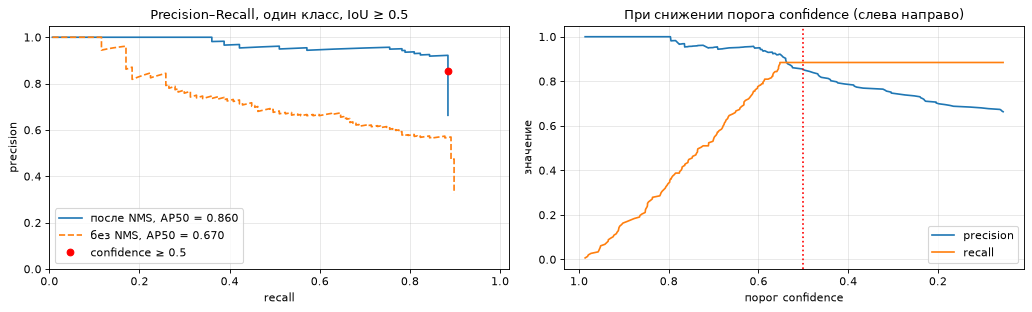

рабочая точка confidence ≥ 0.5: precision = 0.855, recall = 0.884
максимально достижимый recall: 0.884 — выше не подняться ни при каком пороге


In [8]:
recs_raw, _ = evaluate(data, keep_key=None)
prec_raw, rec_raw = pr_curve(recs_raw, N_GT)
scores_sorted = np.array([r["score"] for r in recs])

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(rec, prec, label=f"после NMS, AP50 = {ap50:.3f}")
ax[0].plot(rec_raw, prec_raw, "--", label=f"без NMS, AP50 = {average_precision(prec_raw, rec_raw):.3f}")
i_op = np.searchsorted(-scores_sorted, -CONF_OPERATING, side="right") - 1
ax[0].plot(rec[i_op], prec[i_op], "ro", label=f"confidence ≥ {CONF_OPERATING}")
ax[0].set(title="Precision–Recall, один класс, IoU ≥ 0.5", xlabel="recall", ylabel="precision", xlim=(0, 1.02), ylim=(0, 1.05)); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].plot(scores_sorted, prec, label="precision"); ax[1].plot(scores_sorted, rec, label="recall")
ax[1].invert_xaxis(); ax[1].axvline(CONF_OPERATING, color="r", ls=":")
ax[1].set(title="При снижении порога confidence (слева направо)", xlabel="порог confidence", ylabel="значение"); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"рабочая точка confidence ≥ {CONF_OPERATING}: precision = {prec[i_op]:.3f}, recall = {rec[i_op]:.3f}")
print(f"максимально достижимый recall: {rec[-1]:.3f} — выше не подняться ни при каком пороге")

### Шаг 10. AP50 и AP50-95 своей реализацией

AP50-95 — среднее AP по десяти порогам IoU от 0.50 до 0.95. Чем выше порог, тем точнее должна быть локализация, чтобы предсказание засчитали.

Сравнение с библиотечным mAP не выполнено (см. оговорку в начале ноутбука).

In [9]:
aps = {}
for t in np.arange(0.5, 0.96, 0.05):
    r_, _ = evaluate(data, match_iou=float(t)); p_, rc_ = pr_curve(r_, N_GT); aps[round(float(t), 2)] = average_precision(p_, rc_)
print("AP по порогам IoU:", {k: round(v, 3) for k, v in aps.items()})
print(f"AP50 = {aps[0.5]:.4f}, AP75 = {aps[0.75]:.4f}, AP50-95 = {np.mean(list(aps.values())):.4f}")

AP по порогам IoU: {0.5: 0.86, 0.55: 0.86, 0.6: 0.86, 0.65: 0.86, 0.7: 0.86, 0.75: 0.86, 0.8: 0.839, 0.85: 0.491, 0.9: 0.117, 0.95: 0.002}
AP50 = 0.8602, AP75 = 0.8602, AP50-95 = 0.6611


### Таблица эксперимента: порог NMS

Precision и recall — в рабочей точке confidence ≥ 0.5.

In [10]:
print(f"{'NMS IoU thr':>12}{'Boxes before':>14}{'Boxes after':>13}{'Precision':>11}{'Recall':>9}{'AP50':>8}{'дубликатов (FP на найденном объекте)':>40}")
for thr in (0.3, 0.5, 0.7, 0.9, None):
    for d in data:
        d["k"] = nms_greedy(d["boxes"], d["scores"], thr) if thr is not None else np.arange(len(d["boxes"]))
    r_, _ = evaluate(data, keep_key="k")
    p_, rc_ = pr_curve(r_, N_GT)
    sc = np.array([x["score"] for x in r_]); i_ = np.searchsorted(-sc, -CONF_OPERATING, side="right") - 1
    dups = sum((not x["tp"]) and x["best_iou"] >= MATCH_IOU for x in r_)
    print(f"{('без NMS' if thr is None else thr):>12}{N_PRED:14d}{len(r_):13d}{p_[i_]:11.3f}{rc_[i_]:9.3f}{average_precision(p_, rc_):8.3f}{dups:40d}")

 NMS IoU thr  Boxes before  Boxes after  Precision   Recall    AP50    дубликатов (FP на найденном объекте)
         0.3           405          186      0.850    0.850   0.827                                       0
         0.5           405          196      0.855    0.884   0.860                                       0
         0.7           405          236      0.736    0.891   0.823                                      39
         0.9           405          398      0.500    0.891   0.671                                     200
     без NMS           405          405      0.491    0.891   0.670                                     207


### Шаг 11. Разбор FP и FN

Каждой ошибке автоматически назначается причина.

- **FP:** *дубликат* — рамка хорошо накрывает объект (IoU ≥ 0.5), но объект уже засчитан более уверенному предсказанию; *плохая локализация* — рамка задевает объект, но IoU < 0.5; *фон* — рамка почти не пересекается ни с одним объектом.
- **FN:** *детектор не нашёл* — ни одного предсказания с IoU ≥ 0.5 не было даже до NMS; *удалён NMS* — подходящее предсказание было, но NMS его выбросила.

In [11]:
def fp_reason(r):
    if r["best_iou"] >= MATCH_IOU: return "дубликат"
    return "плохая локализация" if r["best_iou"] >= 0.1 else "фон"

fps = [r for r in recs if not r["tp"]]
print(f"FP после NMS: {len(fps)}; по причинам:", {k: sum(fp_reason(r) == k for r in fps) for k in ("дубликат", "плохая локализация", "фон")})
print(f"{'изобр.':>7}{'conf':>7}{'max IoU с GT':>14}  причина")
for reason in ("плохая локализация", "фон", "дубликат"):
    for r in [r for r in fps if fp_reason(r) == reason][:3]: print(f"{r['img']:7d}{r['score']:7.2f}{r['best_iou']:14.2f}  {reason}")

fns = []
for img_id, d in enumerate(data):
    for j in np.nonzero(~used[img_id])[0]:
        iou_all = iou_matrix(d["boxes"], d["gt"][j])[:, 0] if len(d["boxes"]) else np.zeros(0)
        had = bool((iou_all >= MATCH_IOU).any())
        kept = bool((iou_all[d["keep"]] >= MATCH_IOU).any()) if len(d["keep"]) else False
        reason = "детектор не нашёл" if not had else ("удалён NMS" if not kept else "занят другим объектом")
        fns.append((img_id, j, float(iou_all.max()) if len(iou_all) else 0.0, reason))
print(f"\nFN: {len(fns)}; по причинам:", {k: sum(f[3] == k for f in fns) for k in sorted(set(f[3] for f in fns))})
print(f"{'изобр.':>7}{'GT №':>6}{'max IoU предсказаний':>22}  причина")
for f in sorted(fns, key=lambda f: f[3] == "детектор не нашёл")[:7]: print(f"{f[0]:7d}{f[1]:6d}{f[2]:22.2f}  {f[3]}")

FP после NMS: 66; по причинам: {'дубликат': 0, 'плохая локализация': 29, 'фон': 37}
 изобр.   conf  max IoU с GT  причина
     16   0.80          0.20  плохая локализация
     36   0.78          0.20  плохая локализация
     33   0.76          0.20  плохая локализация
      8   0.60          0.00  фон
     19   0.58          0.00  фон
     12   0.57          0.00  фон

FN: 17; по причинам: {'детектор не нашёл': 15, 'занят другим объектом': 1, 'удалён NMS': 1}
 изобр.  GT №  max IoU предсказаний  причина
     36     4                  0.89  занят другим объектом
     38     4                  0.54  удалён NMS
      0     1                  0.00  детектор не нашёл
      1     3                  0.12  детектор не нашёл
      7     1                  0.01  детектор не нашёл
      7     2                  0.00  детектор не нашёл
     17     0                  0.00  детектор не нашёл


## 5. Неудачный случай: NMS в плотной сцене

Два человека стоят рядом, один частично закрывает другого. Их настоящие рамки сильно перекрываются. Пусть детектор сработал **идеально** — выдал точные рамки обоих.

IoU между двумя настоящими объектами: 0.548
  NMS thr = 0.3: оставлено 1 из 2 → второй человек потерян, хотя детектор его нашёл
  NMS thr = 0.5: оставлено 1 из 2 → второй человек потерян, хотя детектор его нашёл
  NMS thr = 0.7: оставлено 2 из 2 → оба объекта найдены


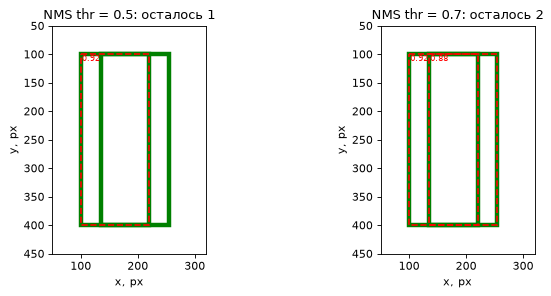

In [12]:
gt_crowd = np.array([[100.0, 100, 220, 400], [135, 100, 255, 400]])
pred_crowd = gt_crowd.copy(); conf_crowd = np.array([0.92, 0.88])
print("IoU между двумя настоящими объектами:", round(iou_matrix(gt_crowd[0], gt_crowd[1])[0, 0], 3))
for thr in (0.3, 0.5, 0.7):
    keep = nms_greedy(pred_crowd, conf_crowd, thr)
    print(f"  NMS thr = {thr}: оставлено {len(keep)} из 2 → {'оба объекта найдены' if len(keep) == 2 else 'второй человек потерян, хотя детектор его нашёл'}")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
for a_, thr in zip(ax, (0.5, 0.7)):
    keep = nms_greedy(pred_crowd, conf_crowd, thr)
    draw(a_, gt_crowd, "green", lw=4); draw(a_, pred_crowd[keep], "red", ls="--", scores=conf_crowd[keep])
    a_.set(xlim=(50, 320), ylim=(450, 50), title=f"NMS thr = {thr}: осталось {len(keep)}", xlabel="x, px", ylabel="y, px"); a_.set_aspect("equal")
plt.tight_layout(); plt.show()

NMS не различает «две рамки на одном объекте» и «две рамки на двух перекрывающихся объектах»: она видит только IoU. Настоящие рамки здесь перекрываются с IoU ≈ 0.55. При пороге 0.5 (и ниже) правильное предсказание второго человека удаляется как «дубликат» — ошибка возникает **после** детектора, на этапе постобработки. При высоком пороге оба сохраняются, но тогда в обычных сценах выживают настоящие дубликаты (таблица эксперимента). Единого правильного порога нет; это компромисс, зависящий от того, насколько плотно расположены объекты.

Вторая ошибка жадности: NMS оставляет самую **уверенную** рамку, а не самую **точную**. Если у дубликата локализация лучше, но confidence ниже, выживет менее точная рамка.

## 6. Вывод

Цифры — из ячеек выше; данные синтетические.

- **Ручные расчёты:** IoU = 2/11 ≈ 0.182; после NMS остаются A и C; precision/recall по шагам совпали с кодом; AP для этого примера — 0.625.
- **Проверка реализаций.** Векторная IoU совпадает с попарной и с `torchvision.ops.box_iou`; собственная NMS даёт те же индексы, что `torchvision.ops.nms`, на всех 40 изображениях.
- **Что делает NMS.** До NMS — 405 рамок на 147 объектов (2.76 на объект), после NMS с порогом 0.5 — 196. Без NMS каждая лишняя рамка на уже найденном объекте считается FP: 207 дубликатов, precision 0.49, AP50 0.67. С NMS дубликатов 0, precision 0.855, AP50 0.86. Recall при этом почти не изменился (0.891 → 0.884): объект находит самая уверенная рамка, а она остаётся.
- **Порог NMS** (таблица эксперимента):

| NMS IoU thr | Boxes before | Boxes after | Precision | Recall | AP50 |
|---|---|---|---|---|---|
| 0.3 | 405 | 186 | 0.850 | 0.850 | 0.827 |
| 0.5 | 405 | 196 | 0.855 | 0.884 | 0.860 |
| 0.7 | 405 | 236 | 0.736 | 0.891 | 0.823 |
| 0.9 | 405 | 398 | 0.500 | 0.891 | 0.671 |
| без NMS | 405 | 405 | 0.491 | 0.891 | 0.670 |

  При высоком пороге (0.7, 0.9) NMS удаляет слишком мало: выживают 39 и 200 дубликатов, precision падает. При низком (0.3) — слишком много: recall снизился с 0.884 до 0.850, потому что вместе с дубликатами удалены верные рамки **соседних** объектов, перекрывавшихся с более уверенной рамкой. Лучший AP50 на этих данных — при пороге 0.5.
- **Снижение порога confidence** (правый график шага 9). Recall растёт до 0.884 и останавливается: 17 объектов из 147 не найдены, и никакой порог их не вернёт. Дальнейшее снижение порога добавляет только ложные срабатывания, и precision падает. В рабочей точке confidence ≥ 0.5: precision 0.855, recall 0.884.
- **AP при разных порогах IoU.** От 0.5 до 0.75 AP не меняется (0.860), при 0.85 падает до 0.49, при 0.9 — до 0.12, при 0.95 — почти ноль; AP50-95 = 0.661. Основные рамки в этих данных сдвинуты на несколько процентов размера объекта: такой точности хватает для IoU 0.75, но не для 0.9. AP50-95 измеряет именно точность локализации, чего AP50 не видит.
- **Типы ошибок** (шаг 11). FP после NMS — 66: 37 фоновых срабатываний и 29 плохо локализованных рамок; дубликатов не осталось. FN — 17: 15 объектов детектор не нашёл вовсе, один потерян из-за NMS, у одного подходящую рамку «забрал» соседний объект.
- **Не сделано:** работа с реальным детектором и сравнение с библиотечным mAP. Данные синтетические, и числа характеризуют генератор, а не какой-либо детектор.

## 7. Вопросы на защиту

**1. Как геометрически вычисляется IoU и что происходит при отсутствии пересечения?**
Пересечение двух осевых прямоугольников — прямоугольник с левым краем $\max(x_1^A,x_1^B)$, правым $\min(x_2^A,x_2^B)$ и аналогично по $y$. Его площадь делится на площадь объединения $=S_A+S_B-S_{\cap}$. Если рамки не пересекаются, ширина или высота пересечения выходит отрицательной; её обрезают до нуля, и IoU = 0. Отсюда недостаток IoU как меры: для непересекающихся рамок оно всегда 0 и не говорит, далеко они друг от друга или почти касаются.

**2. Почему NMS является жадным алгоритмом и в каких сценах она может ошибаться?**
На каждом шаге она принимает самую уверенную рамку и безвозвратно удаляет её соседей, не рассматривая, не лучше ли было бы другое подмножество рамок. Решение зависит от порядка: в вопросе 2 рамка C выжила только потому, что B была удалена раньше. Ошибается в плотных сценах (толпа, стая, полка с товарами), где настоящие объекты перекрываются сильнее порога, — удаляет верные предсказания; и когда самая уверенная рамка не самая точная.

**3. Участок собственного NMS; порядок сортировки и удаления.**
В `nms_greedy`: `order = np.argsort(-scores)` — индексы по убыванию confidence. В цикле `best = order[0]` — текущая самая уверенная рамка, она добавляется в `keep`. `iou_matrix(boxes[best], boxes[order[1:]])` — её IoU со всеми оставшимися. `order = order[1:][ious <= thr]` — из очереди убираются она сама и все рамки с IoU выше порога; остальные сохраняют порядок. Цикл заканчивается, когда очередь пуста. Возвращаются индексы в порядке убывания confidence — как у `torchvision.ops.nms`.